In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import seaborn as sns
import importlib
import bcifswsni_bn
importlib.reload(bcifswsni_bn)

from bcifswsni_bn import run_model
import nibabel as nib


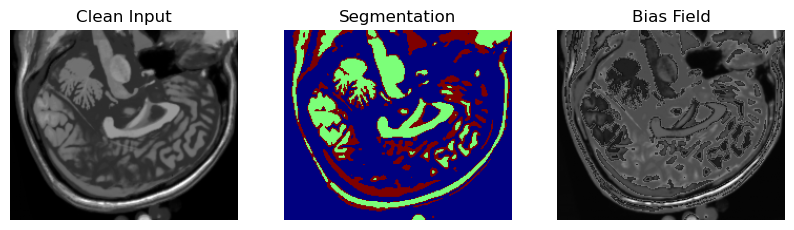

In [5]:
# CLEAN CASE

img_3d = nib.load("clean.mnc").get_fdata()
img = img_3d[:, :, 90]

img = (img - img.min()) / (img.max() - img.min() + 1e-8)

seg, _, _, B = run_model(
    img,
    c=3,
    m=2,
    a_=0.2,
    g="yager",
    e=1e-5,
    max_iter=100,
    p=1.0
)

plt.figure(figsize=(10,4))

plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title("Clean Input")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(seg, cmap='jet')
plt.title("Segmentation")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(B.reshape(img.shape), cmap='gray')
plt.title("Bias Field")
plt.axis('off')

plt.show()